# Lab 1. Spectral analysis of deterministic signals - variant 7

X[μ] = [6, 8, 2, 4, 3, 4, 5, 0, 0, 0]ᵀ, N₀ = 10

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import ifft

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})
np.set_printoptions(precision=3, suppress=True, linewidth=250)

X = np.array([6, 8, 2, 4, 3, 4, 5, 0, 0, 0], dtype=complex).reshape(-1, 1)
N0 = X.shape[0]
print("N0 =", N0)
print("X[mu] =", X.real.ravel())

N0 = 10
X[mu] = [6. 8. 2. 4. 3. 4. 5. 0. 0. 0.]


## Index matrix K, Fourier matrix W and IDFT

In [2]:
def build_K_W(N):
    k = np.arange(N).reshape(-1, 1)
    mu = np.arange(N).reshape(1, -1)
    K = k @ mu
    W = np.exp(+1j*2*np.pi/N*K)
    return K, W

def pad_X(X, N):
    Xp = np.zeros((N, 1), dtype=complex)
    n = min(N, X.shape[0])
    Xp[:n] = X[:n]
    return Xp

def idft_matrix(X, N):
    K, W = build_K_W(N)
    return 1/N * (W @ X), K, W

## Matrices K and W for N = N0 = 10

In [3]:
x0, K, W = idft_matrix(X, N0)
print("K =")
print(K)
print("W (real part) =")
print(W.real)
print("W (imaginary part) =")
print(W.imag)

K =
[[ 0  0  0  0  0  0  0  0  0  0]
 [ 0  1  2  3  4  5  6  7  8  9]
 [ 0  2  4  6  8 10 12 14 16 18]
 [ 0  3  6  9 12 15 18 21 24 27]
 [ 0  4  8 12 16 20 24 28 32 36]
 [ 0  5 10 15 20 25 30 35 40 45]
 [ 0  6 12 18 24 30 36 42 48 54]
 [ 0  7 14 21 28 35 42 49 56 63]
 [ 0  8 16 24 32 40 48 56 64 72]
 [ 0  9 18 27 36 45 54 63 72 81]]
W (real part) =
[[ 1.     1.     1.     1.     1.     1.     1.     1.     1.     1.   ]
 [ 1.     0.809  0.309 -0.309 -0.809 -1.    -0.809 -0.309  0.309  0.809]
 [ 1.     0.309 -0.809 -0.809  0.309  1.     0.309 -0.809 -0.809  0.309]
 [ 1.    -0.309 -0.809  0.809  0.309 -1.     0.309  0.809 -0.809 -0.309]
 [ 1.    -0.809  0.309  0.309 -0.809  1.    -0.809  0.309  0.309 -0.809]
 [ 1.    -1.     1.    -1.     1.    -1.     1.    -1.     1.    -1.   ]
 [ 1.    -0.809  0.309  0.309 -0.809  1.    -0.809  0.309  0.309 -0.809]
 [ 1.    -0.309 -0.809  0.809  0.309 -1.     0.309  0.809 -0.809 -0.309]
 [ 1.     0.309 -0.809 -0.809  0.309  1.     0.309 -0.809 -0.809 

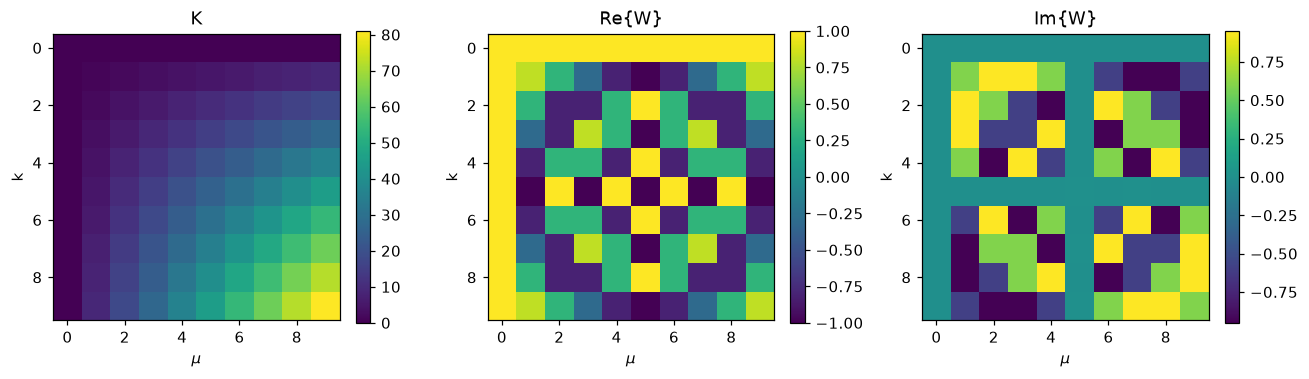

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, M, t in zip(ax, [K, W.real, W.imag], ["K", "Re{W}", "Im{W}"]):
    im = a.imshow(M, cmap="viridis")
    a.set_title(t); a.set_xlabel(r"$\mu$"); a.set_ylabel("k"); a.grid(False)
    fig.colorbar(im, ax=a, fraction=0.046)
fig.tight_layout()
fig.savefig("fig_matrices.png", bbox_inches="tight")
plt.show()

## Matrix properties

In [5]:
print("W^H W = N I :", np.allclose(W.conj().T @ W, N0*np.eye(N0)))
print("W symmetric :", np.allclose(W, W.T))
print("W^-1 = W*/N :", np.allclose(np.linalg.inv(W), W.conj()/N0))

W^H W = N I : True
W symmetric : True
W^-1 = W*/N : True


## IDFT signal synthesis x = (1/N) W X for different N

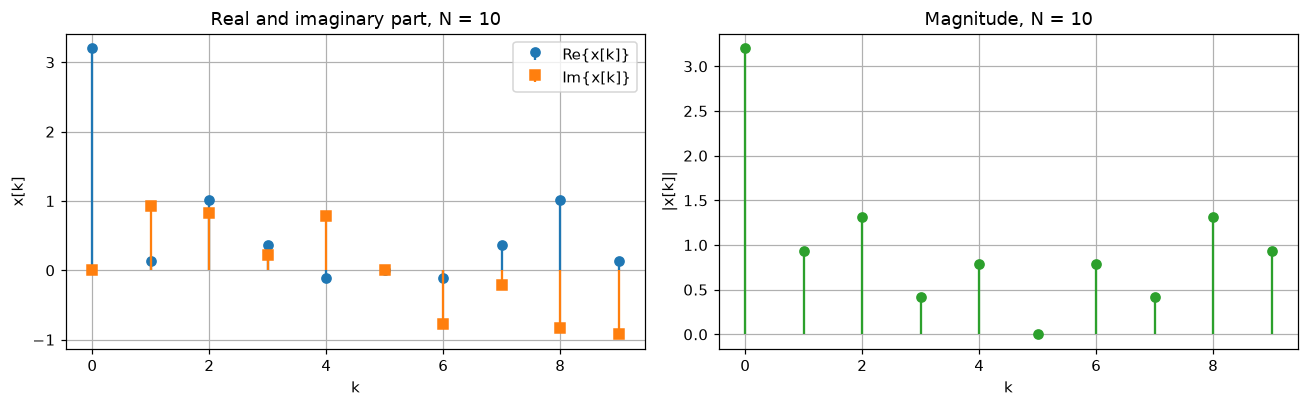

N = 10: max |x - ifft(X)| = 7.78e-16


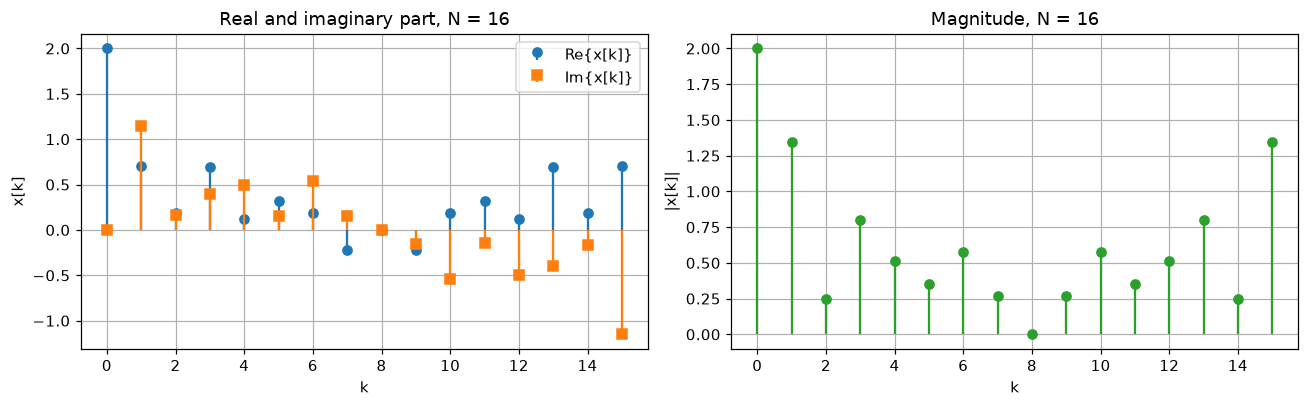

N = 16: max |x - ifft(X)| = 1.40e-15


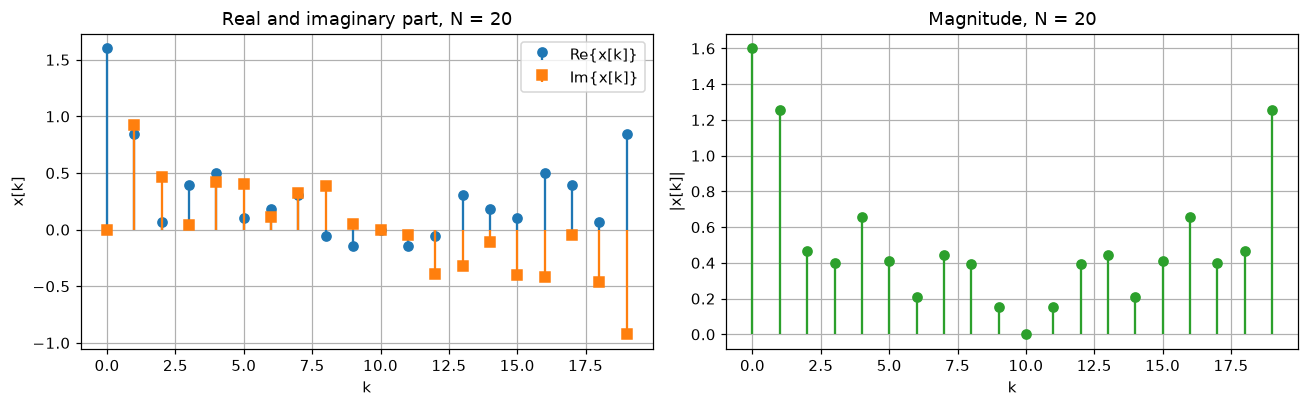

N = 20: max |x - ifft(X)| = 6.59e-16


In [6]:
N_list = [N0, 16, 20]
signals = {}
for N in N_list:
    XN = pad_X(X, N)
    xN, _, _ = idft_matrix(XN, N)
    signals[N] = xN[:, 0]
    n = np.arange(N)

    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].stem(n, xN[:, 0].real, linefmt="C0-", markerfmt="C0o", basefmt=" ", label="Re{x[k]}")
    ax[0].stem(n, xN[:, 0].imag, linefmt="C1-", markerfmt="C1s", basefmt=" ", label="Im{x[k]}")
    ax[0].set_xlabel("k"); ax[0].set_ylabel("x[k]"); ax[0].legend()
    ax[0].set_title(f"Real and imaginary part, N = {N}")
    ax[1].stem(n, np.abs(xN[:, 0]), linefmt="C2-", markerfmt="C2o", basefmt=" ")
    ax[1].set_xlabel("k"); ax[1].set_ylabel("|x[k]|")
    ax[1].set_title(f"Magnitude, N = {N}")
    fig.tight_layout()
    fig.savefig(f"fig_idft_N{N}.png", bbox_inches="tight")
    plt.show()
    print(f"N = {N}: max |x - ifft(X)| = {np.max(np.abs(xN[:, 0] - ifft(XN[:, 0]))):.2e}")

In [7]:
print("x[k] for N = 10:")
print(signals[10])
print("mean(x) = X[0]/N =", np.mean(signals[10]), "| expected", X[0, 0]/N0)
print("max |Im{x}| for N = 10:", np.max(np.abs(signals[10].imag)))

x[k] for N = 10:
[ 3.2  +0.j     0.138+0.923j  1.009+0.833j  0.362+0.218j -0.109+0.778j  0.   -0.j    -0.109-0.778j  0.362-0.218j  1.009-0.833j  0.138-0.923j]
mean(x) = X[0]/N = (0.6000000000000001+1.1102230246251565e-16j) | expected (0.6000000000000001+0j)
max |Im{x}| for N = 10: 0.9233050611525763
